In [1]:
import sgp
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern'],
    'axes.labelsize': 12,   # Font size for axis labels
    'font.size': 12,        # General font size
    'legend.fontsize': 12,  # Font size for legend
    'xtick.labelsize': 12,  # Font size for x-axis tick labels
    'ytick.labelsize': 12   # Font size for y-axis tick labels
})
plt.rcParams["figure.figsize"] = (4, 3)
plt.rc('text', usetex=True)
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath,amssymb,bm}'

In [2]:
nx = 2**7
ny = 2**7

lx = 30
ly = 30

dt = 2e-4

# Chemical potential schedule
def mu_fun(t, tau, mu_i=0.1, mu_f=20.0, t_r=10):
    return mu_i*(t<=t_r) + (mu_i + (mu_f - mu_i) * (t-t_r) / tau)*(t>t_r)*(t<=(t_r+tau)) + mu_f * (t>(t_r+tau))

geo = sgp.Geometry(N=(nx, ny), L=(lx, ly))
dispersion = (geo.kx_**2 + geo.ky_**2) / 2

syst = sgp.System(g_2d=1.0, gamma=0.03, temp=1)
syst.set_geometry(geo)
syst.set_dispersion(dispersion)

psi_initial = 0e-2 * (np.random.default_rng(1).normal(size=(ny, ny)) + 1j * np.random.default_rng(1).normal(size=(nx, ny)))
psi_test = syst.project_low_energy(psi_initial, 50)

In [3]:
psi_t = syst.evolve(psi_0=psi_initial,
                    n_steps=550000,
                    dt=2e-4,
                    e_cut=50,
                    mu=mu_fun,
                    snapshots=20,
                    tau=100,
                    mu_i=0.1,
                    mu_f=20.0,
                    t_r=10)

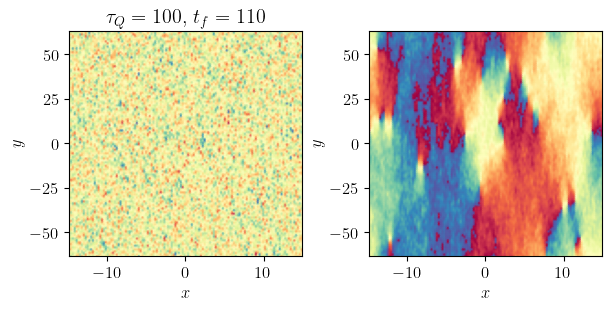

In [6]:
# ----------------------- plot final density -----------------------
fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)

# plt.figure(figsize=(6,5))
im1 = ax[0].pcolormesh(geo.x, geo.y, np.abs(psi_t[19])**2, cmap='Spectral_r', shading='gouraud')
im2 = ax[1].pcolormesh(geo.x, geo.y, np.angle(psi_t[19]), cmap='Spectral_r', shading='gouraud')
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$y$")
ax[1].set_xlabel(r"$x$")
ax[1].set_ylabel(r"$y$")
ax[0].set_title(r"$\tau_Q=%.0f$, $t_f=%.0f$" % (100, 550000*2e-4))
# fig.colorbar(im1, label=r"$|\psi(x, y)|^2$")
# fig.colorbar(im2, label=r"$\theta(x, y)$")
# plt.tight_layout()
plt.show()


In [24]:
int((100+10)/dt)

550000